In [94]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


In [95]:
def load_parameters(path='test.txt'):
    params = {}

    with open(path, 'r', encoding='utf-8') as file:
        for line in file:
            line = line.strip()
            if not line:
                continue
            name, value = line.split('=', 1)
            params[name.strip()] = float(value.strip())

    a_names = [name for name in params if name.startswith('a') and name != 'a0']
    b_names = [name for name in params if name.startswith('b')]

    p = max((int(name[1:]) for name in a_names), default=0)
    q = max((int(name[1:]) for name in b_names), default=0)

    true_theta = [params['a0']]
    true_theta.extend(params[f'a{i}'] for i in range(1, p + 1))
    true_theta.extend(params[f'b{j}'] for j in range(1, q + 1))

    return params, p, q, np.array(true_theta, dtype=float)


def load_test_data(v_path='v.txt', y_path='y.txt', p=3):
    v = np.loadtxt(v_path).reshape(-1)
    y_loaded = np.loadtxt(y_path).reshape(-1)

    if len(y_loaded) == len(v):
        y = y_loaded
    elif len(y_loaded) == len(v) - p:
        y = np.concatenate([v[:p], y_loaded])
    else:
        raise ValueError(
            f'Невідповідність розмірів: len(v)={len(v)}, len(y)={len(y_loaded)}, p={p}'
        )

    return v, y


In [96]:
USE_TEST_DATA = False

if USE_TEST_DATA:
    params, p_true, q_true, true_theta = load_parameters('test.txt')
    v, y = load_test_data('v.txt', 'y.txt', p_true)
    N = len(v)
    subtract_current_v = False
    common_start = max(p_true, q_true)
else:
    a0 = 0.1
    a1 = 0.21
    a2 = 0.32
    a3 = 0.43
    b1 = 0.4
    b2 = 0.4
    b3 = 0.2

    p_true = 3
    q_true = 3
    true_theta = np.array([a0, a1, a2, a3, b1, b2, b3], dtype=float)

    N = 100
    np.random.seed(6)
    v = np.random.normal(0, 1, N)
    y = np.zeros(N)

    for k in range(3, N):
        y[k] = (a0 +
                a1 * y[k-1] + a2 * y[k-2] + a3 * y[k-3] +
                v[k] + b1 * v[k-1] + b2 * v[k-2] + b3 * v[k-3])

    subtract_current_v = True
    common_start = 3

param_names = ['a0'] + [f'a{i}' for i in range(1, p_true + 1)] + [f'b{j}' for j in range(1, q_true + 1)]


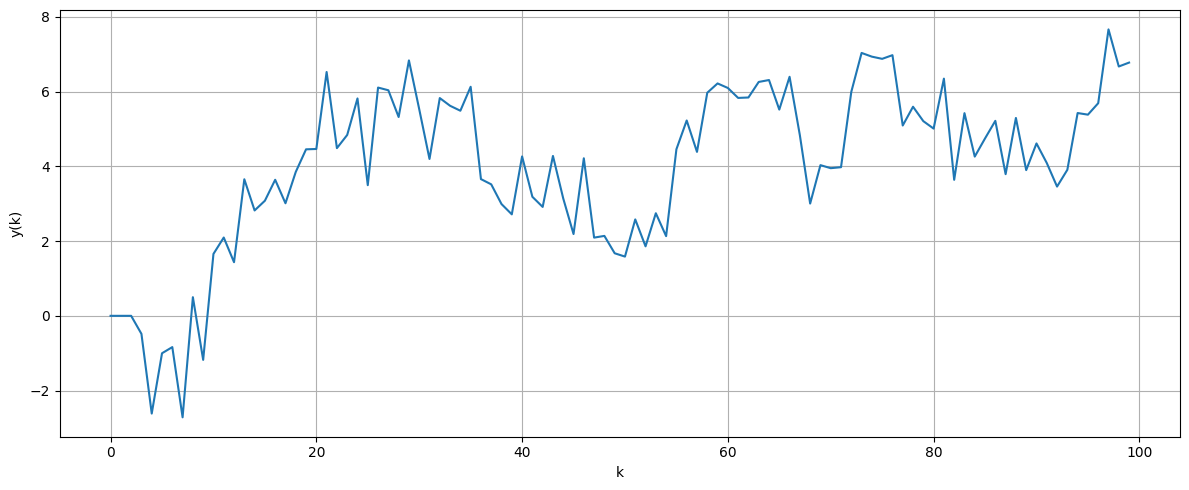

In [97]:
plt.figure(figsize=(12, 5))
plt.plot(y)
plt.xlabel('k')
plt.ylabel('y(k)')
plt.grid(True)
plt.tight_layout()
plt.show()


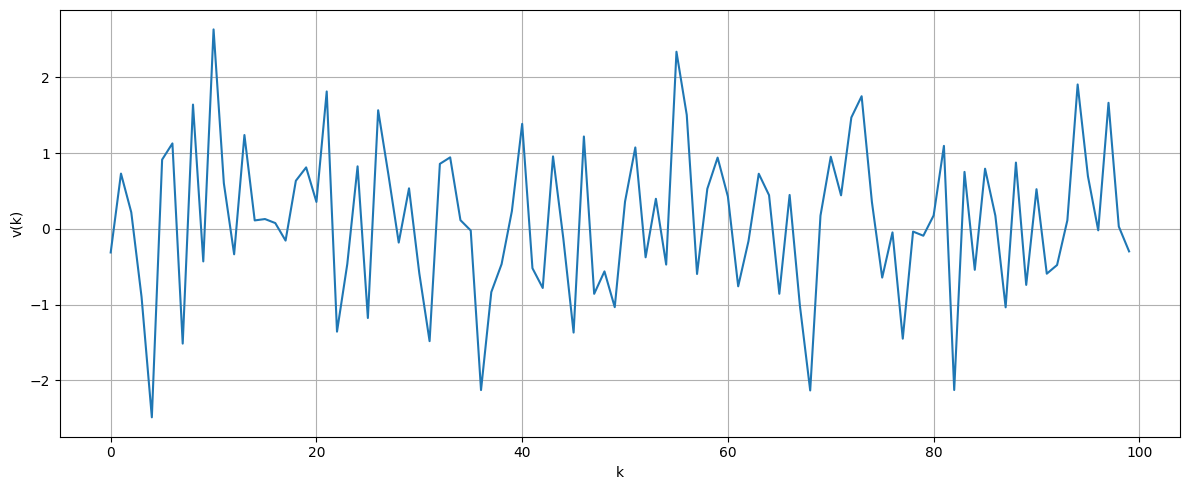

In [98]:
plt.figure(figsize=(12, 5))
plt.plot(v)
plt.xlabel('k')
plt.ylabel('v(k)')
plt.grid(True)
plt.tight_layout()
plt.show()


In [99]:
def prepare_data(p, q, y, v, common_start=3, subtract_current_v=False):
    X = []
    Y_est = []
    Y_actual = []

    start = max(common_start, p, q)

    for k in range(start, len(y)):
        row = [1.0]

        for i in range(1, p + 1):
            row.append(y[k - i])

        for j in range(1, q + 1):
            row.append(v[k - j])

        X.append(row)
        Y_est.append(y[k] - v[k] if subtract_current_v else y[k])
        Y_actual.append(y[k])

    return np.array(X), np.array(Y_est), np.array(Y_actual), start


def mnk(X, Y):
    theta, *_ = np.linalg.lstsq(X, Y, rcond=None)
    return theta


def rmnk(X, Y, beta=1000.0):
    num_samples, num_params = X.shape
    theta = np.zeros(num_params)
    P = np.eye(num_params) * beta
    theta_history = np.zeros((num_samples, num_params))

    for i in range(num_samples):
        x = X[i]
        y_i = Y[i]

        K = (P @ x) / (1.0 + x @ P @ x)
        error = y_i - x @ theta
        theta = theta + K * error
        P = P - np.outer(K, x) @ P
        theta_history[i] = theta

    return theta, theta_history


In [100]:
X, Y_est, Y_actual, start_true = prepare_data(
    p_true,
    q_true,
    y,
    v,
    common_start=common_start,
    subtract_current_v=subtract_current_v
)

theta_rmnk, rmnk_history = rmnk(X, Y_est)

num_samples, num_params = X.shape
mnk_history = np.full((num_samples, num_params), np.nan)

for i in range(1, num_samples + 1):
    Xi = X[:i]
    if i >= num_params and np.linalg.matrix_rank(Xi) == num_params:
        mnk_history[i - 1] = mnk(Xi, Y_est[:i])

k_values = np.arange(start_true, start_true + num_samples)
theta_mnk_final = mnk(X, Y_est)

df_coeff = pd.DataFrame({
    'Коефіцієнт': param_names,
    'Фактичне': true_theta,
    'МНК': theta_mnk_final,
    'РМНК': theta_rmnk
})

df_coeff.round(6)


,Коефіцієнт,Фактичне,МНК,РМНК
0,a0,0.10,0.10,0.099998
1,a1,0.21,0.21,0.210044
2,a2,0.32,0.32,0.319988
3,a3,0.43,0.43,0.429969
4,b1,0.40,0.40,0.399950
5,b2,0.40,0.40,0.399980
6,b3,0.20,0.20,0.200000


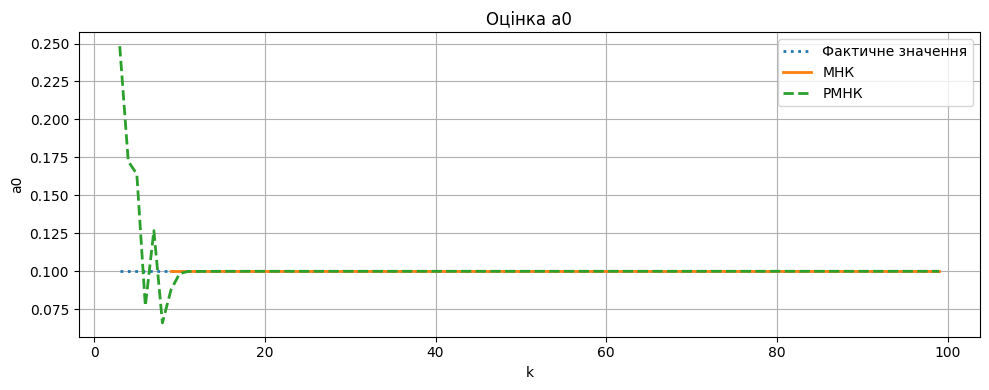

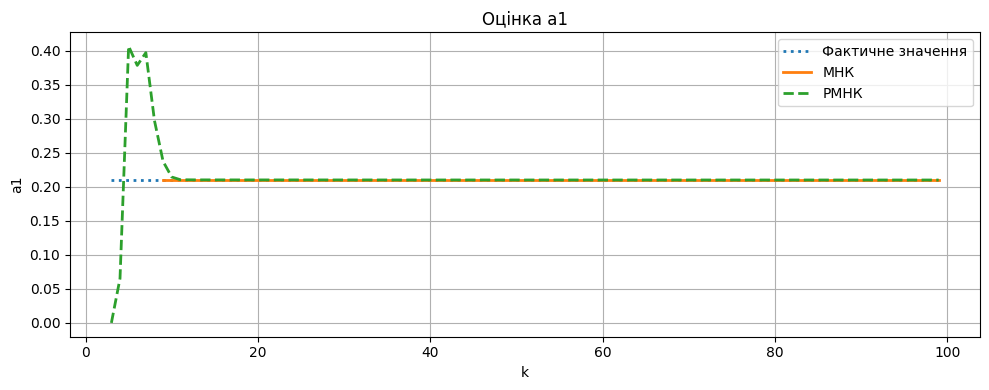

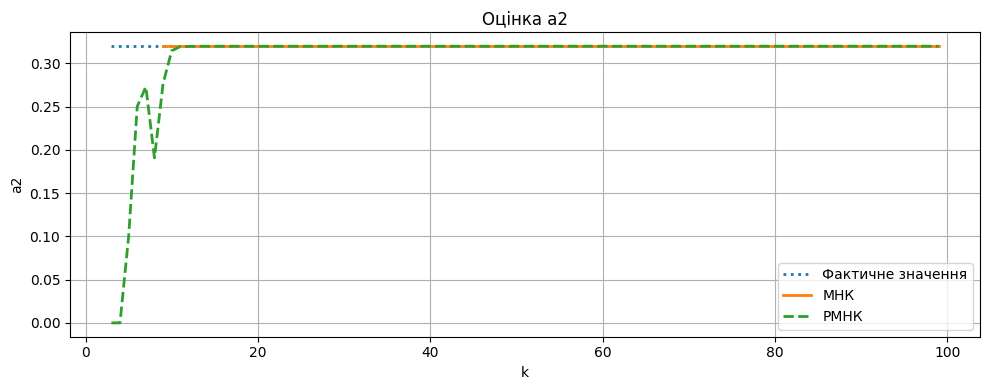

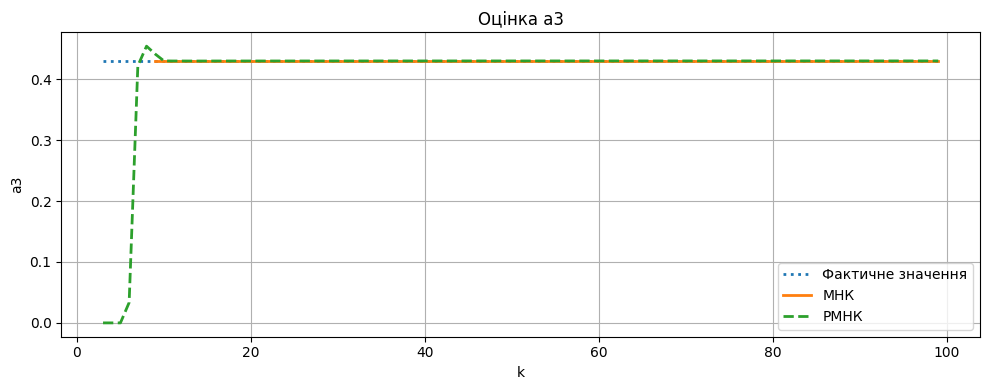

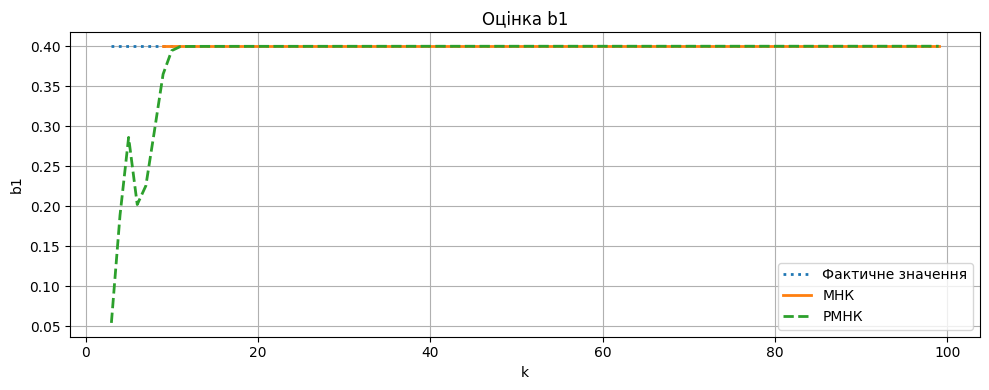

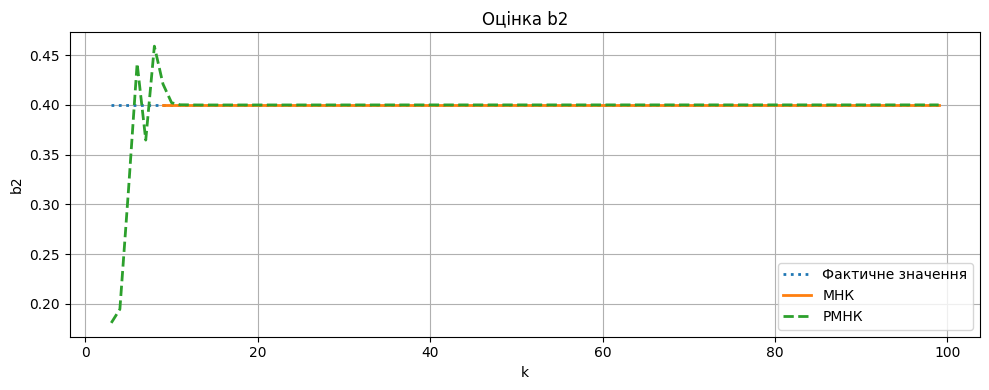

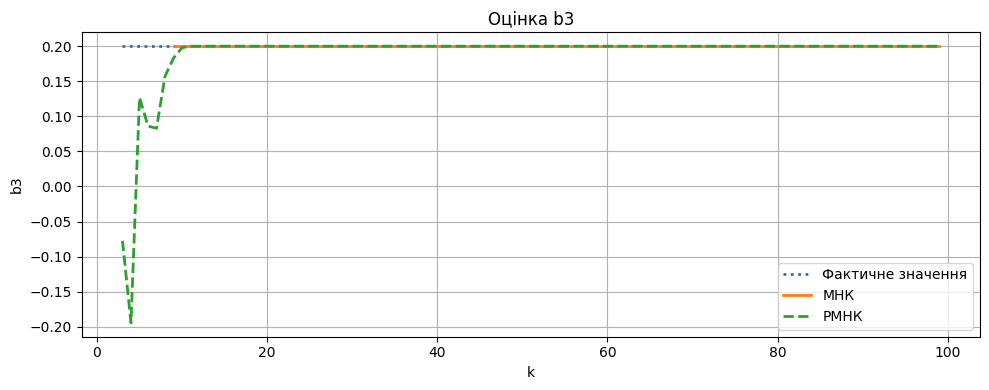

In [101]:
for j in range(num_params):
    plt.figure(figsize=(10, 4))
    plt.plot(k_values, [true_theta[j]] * num_samples, linestyle=':', linewidth=2, label='Фактичне значення')
    plt.plot(k_values, mnk_history[:, j], linestyle='-', linewidth=2, label='МНК')
    plt.plot(k_values, rmnk_history[:, j], linestyle='--', linewidth=2, label='РМНК')
    plt.title(f'Оцінка {param_names[j]}')
    plt.xlabel('k')
    plt.ylabel(param_names[j])
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [102]:
results = []
models_names = []

for p_test in range(1, 4):
    for q_test in range(1, 4):
        model_name = f'АРКС({p_test},{q_test})'
        models_names.append(model_name)

        X_test, Y_est_test, Y_actual_test, _ = prepare_data(
            p_test,
            q_test,
            y,
            v,
            common_start=common_start,
            subtract_current_v=subtract_current_v
        )

        theta_mnk = mnk(X_test, Y_est_test)
        theta_rmnk, _ = rmnk(X_test, Y_est_test)

        n_params = p_test + q_test + 1
        N_test = len(Y_actual_test)
        var_y = np.var(Y_actual_test)

        metrics = {}

        for method_name, theta_est in [
            ('МНК', theta_mnk),
            ('РМНК', theta_rmnk)
        ]:
            Y_hat = X_test @ theta_est
            e = Y_actual_test - Y_hat
            S = np.sum(e ** 2)
            R2 = np.var(Y_hat) / var_y
            IKA = N_test * np.log(max(S, np.finfo(float).tiny)) + 2 * n_params

            metrics.update({
                f'S_{method_name}': S,
                f'R2_{method_name}': R2,
                f'IKA_{method_name}': IKA
            })

        results.append(metrics)

df_results = pd.DataFrame(results, index=models_names)

display(df_results.round(6))

print('МНК:')
print('мінімальне S ->', df_results['S_МНК'].idxmin())
print('максимальне R2 ->', df_results['R2_МНК'].idxmax())
print('мінімальне IKA ->', df_results['IKA_МНК'].idxmin())

print()
print('РМНК:')
print('мінімальне S ->', df_results['S_РМНК'].idxmin())
print('максимальне R2 ->', df_results['R2_РМНК'].idxmax())
print('мінімальне IKA ->', df_results['IKA_РМНК'].idxmin())


,S_МНК,R2_МНК,IKA_МНК,S_РМНК,R2_РМНК,IKA_РМНК
"АРКС(1,1)",127.114608,0.895013,475.973643,127.114524,0.895010,475.973579
"АРКС(1,2)",123.597233,0.907881,475.251732,123.597146,0.907878,475.251663
"АРКС(1,3)",115.723769,0.917230,470.866987,115.723761,0.917228,470.866980
"АРКС(2,1)",119.865867,0.906297,472.278215,119.865780,0.906296,472.278144
"АРКС(2,2)",121.252112,0.909139,475.393579,121.251518,0.909138,475.393104
"АРКС(2,3)",101.652612,0.928476,460.291440,101.653677,0.928475,460.292456
"АРКС(3,1)",113.990318,0.910523,469.403011,113.990600,0.910522,469.403251
"АРКС(3,2)",105.688160,0.931669,464.067808,105.688283,0.931666,464.067921
"АРКС(3,3)",99.522382,0.935567,460.237109,99.522898,0.935565,460.237612


МНК:
мінімальне S -> АРКС(3,3)
максимальне R2 -> АРКС(3,3)
мінімальне IKA -> АРКС(3,3)

РМНК:
мінімальне S -> АРКС(3,3)
максимальне R2 -> АРКС(3,3)
мінімальне IKA -> АРКС(3,3)


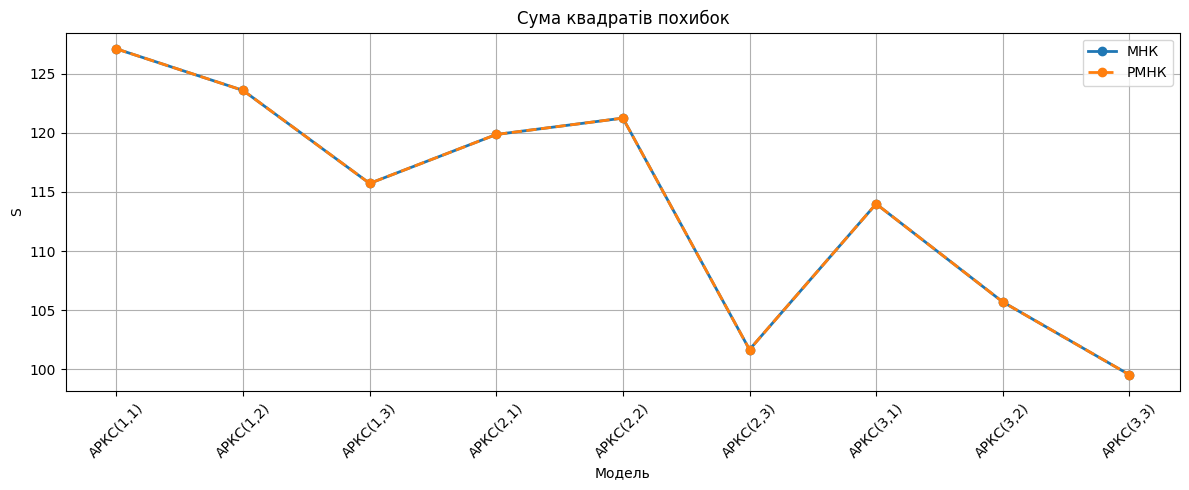

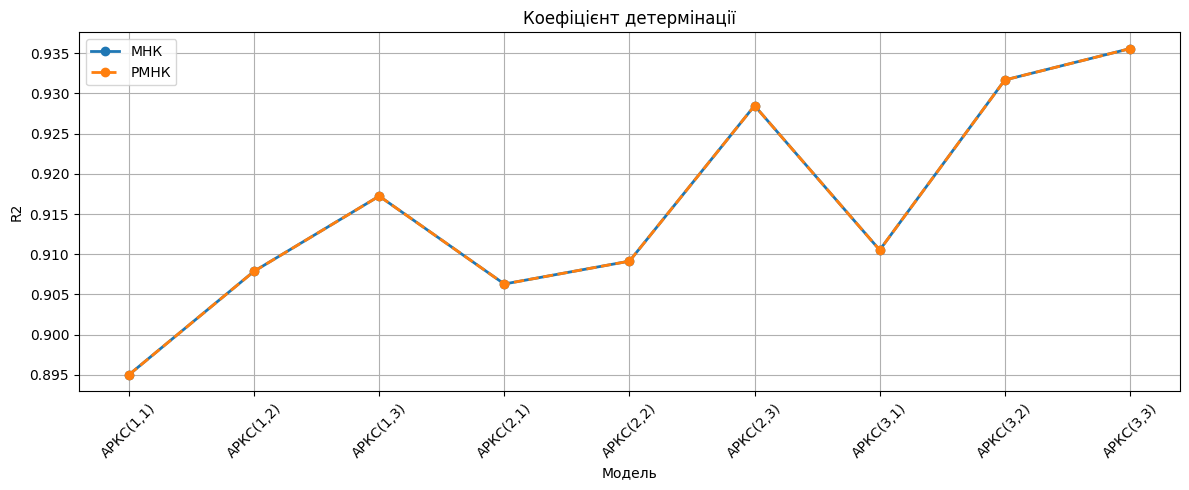

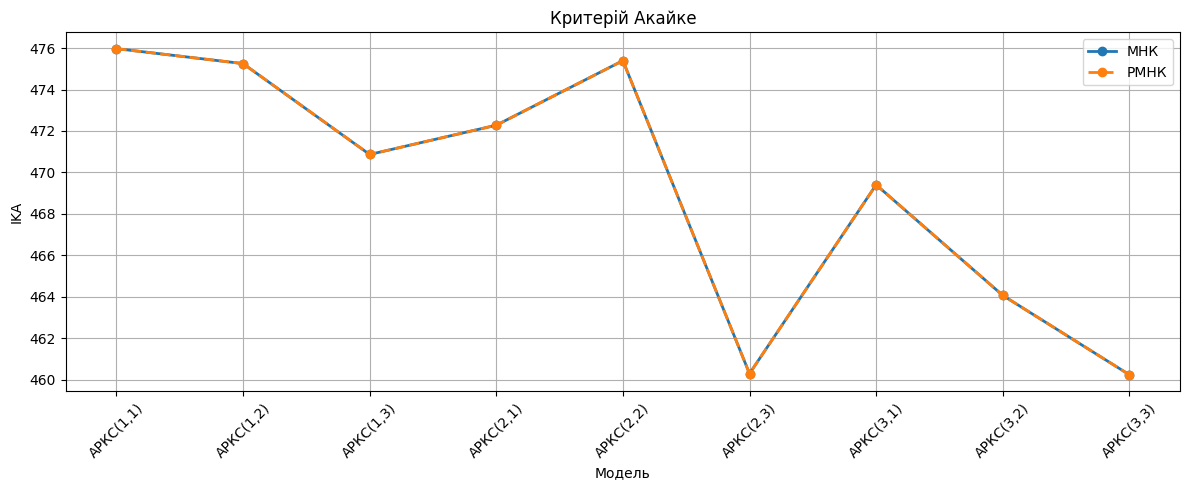

In [103]:
plt.figure(figsize=(12, 5))
plt.plot(models_names, df_results['S_МНК'], marker='o', linestyle='-', linewidth=2, label='МНК')
plt.plot(models_names, df_results['S_РМНК'], marker='o', linestyle='--', linewidth=2, label='РМНК')
plt.title('Сума квадратів похибок')
plt.xlabel('Модель')
plt.ylabel('S')
plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(models_names, df_results['R2_МНК'], marker='o', linestyle='-', linewidth=2, label='МНК')
plt.plot(models_names, df_results['R2_РМНК'], marker='o', linestyle='--', linewidth=2, label='РМНК')
plt.title('Коефіцієнт детермінації')
plt.xlabel('Модель')
plt.ylabel('R2')
plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(models_names, df_results['IKA_МНК'], marker='o', linestyle='-', linewidth=2, label='МНК')
plt.plot(models_names, df_results['IKA_РМНК'], marker='o', linestyle='--', linewidth=2, label='РМНК')
plt.title('Критерій Акайке')
plt.xlabel('Модель')
plt.ylabel('IKA')
plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [104]:
best_s = df_results['S_МНК'].idxmin()
best_r2 = df_results['R2_МНК'].idxmax()
best_ika = df_results['IKA_МНК'].idxmin()

print(f'Істинна структура за test.txt: АРКС({p_true},{q_true})' if USE_TEST_DATA else f'Істинна структура: АРКС({p_true},{q_true})')
print(f'Мінімальне S: {best_s}')
print(f'Максимальне R2: {best_r2}')
print(f'Мінімальне IKA: {best_ika}')


Істинна структура: АРКС(3,3)
Мінімальне S: АРКС(3,3)
Максимальне R2: АРКС(3,3)
Мінімальне IKA: АРКС(3,3)
